# Incendies de forêt en PACA : délais d'accès des sapeurs-pompiers

**Question :** combien de temps faut-il, au minimum, à une caserne de sapeurs-pompiers pour atteindre chaque forêt de la région PACA ? Les communes qui ont beaucoup d'incendies sont-elles bien desservies ?

**Données :**
- Communes : `entites-administratives.shp` (couche des entités administratives de PACA)
- Forêts : `FORMATION_VEGETALE.shp` (BD Forêt v2 de l'IGN)
- Casernes : `casernes_osm.geojson` (OpenStreetMap, `amenity=fire_station`, extrait avec Overpass Turbo)
- Points d'urgence OSM : `osm-urgence-polygonesPolygon.shp` (exploré, mais il ne contient presque pas de casernes)
- Incendies : `Incendies.csv` (BDIFF, feux de forêt 2016-2025)

**Démarche :**
1. Charger les données (toutes en Lambert-93, EPSG:2154, en mètres)
2. Garder les communes de PACA, les casernes et les incendies de PACA
3. Garder les forêts de PACA et les résumer par un point situé à l'intérieur
4. Trouver la caserne la plus proche de chaque forêt (distance à vol d'oiseau)
5. Convertir la distance en délai (hypothèses : détour × 1,3, vitesse 50 km/h)
6. Agréger par commune et fusionner avec le nombre d'incendies
7. Statistiques descriptives, cartes et graphiques

## 0. Imports et paramètres

In [13]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# dossier qui contient toutes les données (un niveau au-dessus de main)
# je cherche le dossier Data en remontant de 0, 1 ou 2 niveaux
dossier_donnees = None
for essai in ["Data", "../Data", "../../Data"]:
    if os.path.exists(essai) and dossier_donnees is None:
        dossier_donnees = essai

print("Dossier de travail :", os.getcwd())
print("Dossier des données :", dossier_donnees)

# petite fonction qui cherche un fichier dans Data et ses sous-dossiers
def trouver_fichier(nom_fichier):
    for racine, sous_dossiers, fichiers in os.walk(dossier_donnees):
        if nom_fichier in fichiers:
            return os.path.join(racine, nom_fichier)
    print("ATTENTION : fichier introuvable :", nom_fichier)
    return None

chemin_communes = trouver_fichier("entites-administratives.shp")
chemin_forets = trouver_fichier("FORMATION_VEGETALE.shp")
chemin_urgences = trouver_fichier("osm-urgence-polygonesPolygon.shp")
chemin_incendies = trouver_fichier("Incendies.csv")
chemin_casernes = trouver_fichier("osm-urgence-polygonesPolygon.shp")
print(chemin_communes, chemin_forets, chemin_urgences, chemin_incendies, chemin_casernes, sep="\n")

# ---- colonnes de la couche communes ----
col_code = "code"   # code INSEE de la commune
col_nom = "nom"     # nom de la commune
col_dep = "dep"     # code du département (je le crée plus bas)

# ---- paramètres de l'étude ----
deps_paca = ["04", "05", "06", "13", "83", "84"]
marge_casernes_m = 20000   # on garde aussi les casernes à moins de 20 km de PACA
surface_min_ha = 1         # on ignore les forêts de moins de 1 hectare
coef_detour = 1.3          # la route est environ 1,3 fois plus longue que la ligne droite
vitesse_kmh = 50           # vitesse moyenne d'un camion d'intervention

# dossier où j'enregistre les cartes et tableaux
os.makedirs("sorties", exist_ok=True)

Dossier de travail : c:\Users\User\Documents\Python\Groupe_KC_AHA_Python\main\Accessibility_temps_de_secours
Dossier des données : ../../Data
../../Data\communes\entites-administratives.shp
../../Data\vegetation\FORMATION_VEGETALE.shp
../../Data\help_centers\osm-urgence-polygonesPolygon.shp
../../Data\fires\Incendies.csv
../../Data\help_centers\osm-urgence-polygonesPolygon.shp


## 1. Chargement des données

In [14]:
# encoding="utf-8" pour bien lire les accents (sinon "RhÃ´ne" au lieu de "Rhône")
df_admin = gpd.read_file(chemin_communes, encoding="utf-8")
df_urgences = gpd.read_file(chemin_urgences)
df_casernes_osm = gpd.read_file(chemin_casernes)

# le CSV de la BDIFF a 3 lignes de titre avant le tableau : skiprows=3
# dtype=str pour garder les codes en texte (04112, 2A092...)
df_incendies = pd.read_csv(
    chemin_incendies,
    sep=";",
    encoding="utf-8",
    skiprows=3,
    dtype={"Code INSEE": str, "Département": str}
)

# je vérifie que tout est bien en Lambert-93
df_admin = df_admin.to_crs(epsg=2154)
df_urgences = df_urgences.to_crs(epsg=2154)
# le fichier d'Overpass Turbo est en latitude/longitude (EPSG:4326) : je le convertis
df_casernes_osm = df_casernes_osm.to_crs(epsg=2154)

print("Entités administratives :", df_admin.shape)
print(df_admin["type"].value_counts())
print("Points d'urgence OSM :", df_urgences.shape)
print("Incendies (France entière) :", df_incendies.shape)
print("Casernes OSM (avant filtre) :", df_casernes_osm.shape)

Entités administratives : (1005, 5)
type
com       945
epci       52
dept        6
COM         1
region      1
Name: count, dtype: int64
Points d'urgence OSM : (2727, 12)
Incendies (France entière) : (27444, 24)
Casernes OSM (avant filtre) : (2727, 12)


## 1 bis. Premier coup d'œil sur les données

Avant tout calcul, je regarde ce que contient chaque table : les premières lignes, les types de colonnes et les valeurs manquantes.

In [15]:
# les incendies
df_incendies.info()

<class 'pandas.DataFrame'>
RangeIndex: 27444 entries, 0 to 27443
Data columns (total 24 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Année                                       27444 non-null  int64  
 1   Numéro                                      27444 non-null  int64  
 2   Département                                 27444 non-null  str    
 3   Code INSEE                                  27444 non-null  str    
 4   Nom de la commune                           27416 non-null  str    
 5   Date de première alerte                     27444 non-null  str    
 6   Surface parcourue (m2)                      27444 non-null  int64  
 7   Surface forêt (m2)                          23995 non-null  float64
 8   Surface maquis garrigues (m2)               12182 non-null  float64
 9   Autres surfaces naturelles hors forêt (m2)  18826 non-null  float64
 10  Surfaces agricoles (m

In [16]:
df_incendies.head()

,Année,Numéro,Département,Code INSEE,Nom de la commune,Date de première alerte,Surface parcourue (m2),Surface forêt (m2),Surface maquis garrigues (m2),Autres surfaces naturelles hors forêt (m2),...,Surfaces non boisées artificialisées (m2),Surfaces non boisées (m2),Précision des surfaces,Type de peuplement,Nature,Décès ou bâtiments touchés,Nombre de décès,Nombre de bâtiments totalement détruits,Nombre de bâtiments partiellement détruits,Précision de la donnée
0,2016,4608,66,66225,Villelongue-dels-Monts,2016-01-01 15:37:00,10,10.0,NaN,NaN,...,NaN,NaN,NaN,3.0,Involontaire (particulier),NaN,NaN,NaN,NaN,NaN
1,2016,6821,66,66026,Brouilla,2016-01-02 11:56:00,10000,10000.0,0.0,NaN,...,NaN,NaN,NaN,2.0,Involontaire (travaux),NaN,NaN,NaN,NaN,NaN
2,2016,12337,66,66106,Maureillas-las-Illas,2016-01-04 13:30:00,20,NaN,20.0,NaN,...,NaN,NaN,NaN,4.0,Malveillance,NaN,NaN,NaN,NaN,NaN
3,2016,6,974,97424,Cilaos,2016-01-05 16:05:00,800,0.0,NaN,800.0,...,0.0,0.0,Estimées,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016,7868,06,06086,Moulinet,2016-01-07 18:36:00,800,NaN,800.0,NaN,...,NaN,NaN,NaN,1.0,Involontaire (particulier),NaN,NaN,NaN,NaN,NaN


In [17]:
# nombre de valeurs manquantes par colonne (les 10 colonnes les plus incomplètes)
df_incendies.isna().sum().sort_values(ascending=False).head(10)

Précision de la donnée                        26487
Nombre de bâtiments partiellement détruits    26237
Nombre de décès                               26236
Nombre de bâtiments totalement détruits       26235
Surfaces non boisées artificialisées (m2)     20946
Autres surfaces (m2)                          20867
Surfaces agricoles (m2)                       20851
Surfaces non boisées naturelles (m2)          20748
Décès ou bâtiments touchés                    19975
Surface autres terres boisées (m2)            18662
dtype: int64

In [18]:
# les communes / départements
print(df_admin.head())
print(df_admin.crs)

       gid  type                      nom code  \
0  25000.0  dept  Alpes-de-Haute-Provence   04   
1  25001.0  dept             Hautes-Alpes   05   
2  25002.0  dept          Alpes-Maritimes   06   
3  25003.0  dept         Bouches-du-Rhône   13   
4  25004.0  dept                      Var   83   

                                            geometry  
0  POLYGON ((910451 6342553, 910622 6342578, 9111...  
1  POLYGON ((933490 6411084, 933531 6411148, 9335...  
2  MULTIPOLYGON (((1029374 6276978, 1029380 62769...  
3  MULTIPOLYGON (((894012 6235138, 894003 6235110...  
4  MULTIPOLYGON (((965894 6216307, 965890 6216315...  
EPSG:2154


In [19]:
# les points d'urgence OSM : quels types contient la couche ?
print(df_urgences["emergency"].value_counts().head(15))
# combien sont vraiment des casernes ?
print("Lignes avec fire_station :", df_urgences["tags"].str.contains("fire_station", na=False).sum())

emergency
water_tank              1719
yes                      266
ambulance_station        145
no                       129
disaster_help_point       94
lifeguard                 71
landing_site              54
mountain_rescue           51
air_rescue_service        31
fire_water_pond           28
water_rescue_station      17
fire_hydrant              16
fire_lookout              15
disaster_response         15
water_rescue              13
Name: count, dtype: int64
Lignes avec fire_station : 4


**Constat :** la couche `osm-urgence` contient surtout des réserves d'eau (`water_tank`), des ambulances, des postes de secours de plage… mais presque **aucune caserne**. En effet, dans OpenStreetMap, une caserne est notée `amenity=fire_station` et pas `emergency=...`. J'ai donc extrait les casernes à part avec Overpass Turbo (`casernes_osm.geojson`).

In [20]:
# les casernes extraites d'OSM
print(df_casernes_osm.head())
print("Types de géométrie :", df_casernes_osm.geom_type.value_counts().to_dict())

         osm_id            emergency                 name access  osm_user  \
0 -2.131944e+07  disaster_help_point  Espace Méditerranée    NaN    LySioS   
1 -1.683634e+07  disaster_help_point     École des Aspres    NaN    LySioS   
2 -5.473583e+06                   no     Clinique Herbert    NaN  zorglubu   
3  1.409777e+09           water_tank                  NaN    NaN  Benoit84   
4  1.410902e+09            lifeguard                  NaN    NaN   delavei   

  osm_timest                                               tags date_impor  \
0 2026-09-02  {"name": "Espace Méditerranée", "leisure": "sp... 2026-10-05   
1 2026-11-06  {"name": "École des Aspres", "email": "ce.0660... 2026-11-06   
2 2020-04-10  {"name": "Clinique Herbert", "amenity": "hospi... 2026-10-05   
3 2025-06-26  {"content": "water", "man_made": "storage_tank... 2026-10-05   
4 2025-06-30      {"building": "yes", "emergency": "lifeguard"} 2026-10-05   

   num_keys  lastmodif    superficie  \
0         4         66

## 2. Préparation : communes de PACA, casernes et incendies

In [21]:
# ---------- COMMUNES DE PACA ----------
# la couche contient des départements ("dept") et des communes ("com") : je garde les communes
df_communes_paca = df_admin[df_admin["type"] == "com"].copy()
# les 2 premiers caractères du code INSEE = le département
df_communes_paca[col_dep] = df_communes_paca[col_code].str[:2]
df_communes_paca = df_communes_paca[df_communes_paca[col_dep].isin(deps_paca)].copy()
print("Communes en PACA :", len(df_communes_paca))

# contour de la région (toutes les communes fusionnées en une seule forme)
contour_paca = df_communes_paca.union_all()
zone_casernes = contour_paca.buffer(marge_casernes_m)

# ---------- CASERNES ----------
df_casernes = df_casernes_osm.copy()
# certaines casernes n'ont pas de nom dans OSM
if "name" not in df_casernes.columns:
    df_casernes["name"] = "Sans nom"
df_casernes["name"] = df_casernes["name"].fillna("Sans nom")

# les polygones deviennent des points
df_casernes["geometry"] = df_casernes.geometry.centroid
# je garde les casernes dans PACA ou juste à côté
df_casernes = df_casernes[df_casernes.within(zone_casernes)].copy()
print("Casernes retenues :", len(df_casernes))
if len(df_casernes) == 0:
    print("ATTENTION : aucune caserne trouvée, la suite ne pourra pas marcher !")

# ---------- INCENDIES ----------
df_incendies["Code INSEE"] = df_incendies["Code INSEE"].astype(str).str.zfill(5)
df_incendies["dep"] = df_incendies["Département"].astype(str).str.zfill(2)
df_incendies_paca = df_incendies[df_incendies["dep"].isin(deps_paca)].copy()
print("Incendies en PACA :", len(df_incendies_paca))

nb_incendies = df_incendies_paca.groupby("Code INSEE").size().reset_index(name="nb_incendies")

Communes en PACA : 944
Casernes retenues : 777
Incendies en PACA : 5940


## 2 bis. Statistiques descriptives des incendies en PACA (2016-2025)

In [22]:
# je convertis les surfaces en nombres, puis en hectares
df_incendies_paca["surface_ha"] = pd.to_numeric(df_incendies_paca["Surface parcourue (m2)"], errors="coerce") / 10000
df_incendies_paca["surface_ha"].describe().round(2)

count    5940.00
mean        5.84
std       111.22
min         0.00
25%         0.00
50%         0.03
75%         0.22
max      6832.00
Name: surface_ha, dtype: float64

In [23]:
# nombre d'incendies et surface brûlée par département
tableau_inc_dep = df_incendies_paca.groupby("dep").agg(
    nb_incendies=("Code INSEE", "count"),
    surface_totale_ha=("surface_ha", "sum"),
    surface_moyenne_ha=("surface_ha", "mean")
).round(1)
tableau_inc_dep.to_csv("sorties/incendies_par_departement.csv")
tableau_inc_dep

,nb_incendies,surface_totale_ha,surface_moyenne_ha
dep,,,
04,594,2792.2,4.7
05,238,477.8,2.0
06,844,3035.5,3.6
13,2699,10873.3,4.0
83,1136,15625.3,13.8
84,429,1903.8,4.4


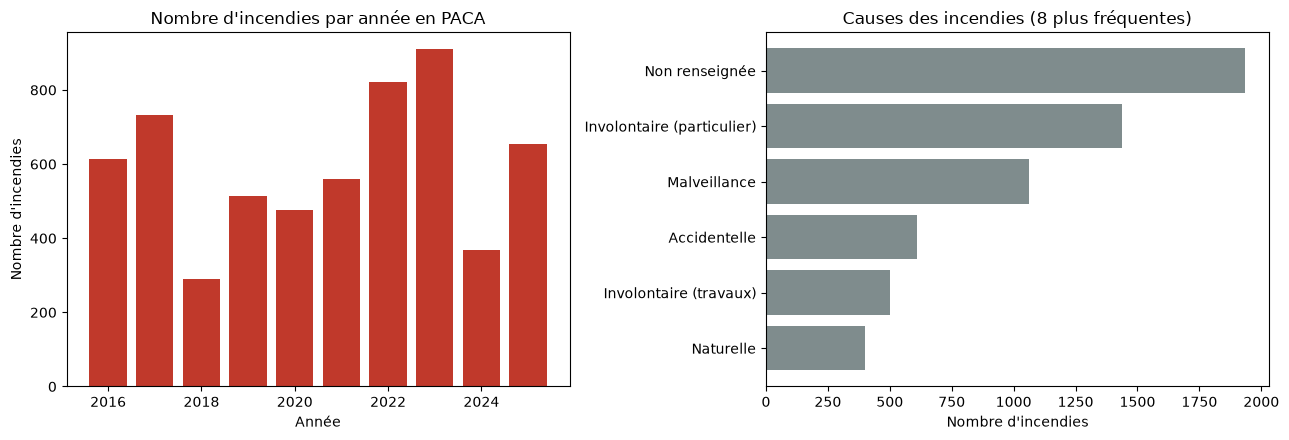

In [24]:
# évolution par année et causes
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

par_annee = df_incendies_paca.groupby("Année").size()
axes[0].bar(par_annee.index, par_annee.values, color="#c0392b")
axes[0].set_title("Nombre d'incendies par année en PACA")
axes[0].set_xlabel("Année")
axes[0].set_ylabel("Nombre d'incendies")

causes = df_incendies_paca["Nature"].fillna("Non renseignée").value_counts().head(8)
axes[1].barh(causes.index, causes.values, color="#7f8c8d")
axes[1].invert_yaxis()   # la cause la plus fréquente en haut
axes[1].set_title("Causes des incendies (8 plus fréquentes)")
axes[1].set_xlabel("Nombre d'incendies")

plt.tight_layout()
plt.savefig("sorties/incendies_annees_causes.png", dpi=300, bbox_inches="tight")
plt.show()

**Pourquoi une marge de 20 km pour les casernes ?** Une forêt située au bord de la région peut être plus proche d'une caserne de la Drôme ou de l'Isère que d'une caserne de PACA. Sans cette marge, on surestimerait les délais près des limites régionales. C'est ce qu'on appelle l'**effet de bord**.

## 3. Les forêts de PACA, un point par forêt

In [25]:
# mask=contour_paca : je lis SEULEMENT les forêts qui touchent PACA (beaucoup plus rapide)
df_forets = gpd.read_file(chemin_forets, mask=contour_paca)
df_forets = df_forets.to_crs(epsg=2154)
print("Polygones de végétation lus :", len(df_forets))
print(df_forets["CODE_TFV"].str[:2].value_counts())

# BD Forêt : les codes qui commencent par "F" sont des forêts (FF = fermée, FO = ouverte, FP = peupleraie)
# les codes "LA" (landes) ne sont pas des forêts : je les retire
df_forets = df_forets[df_forets["CODE_TFV"].str.startswith("F")].copy()

# surface de chaque forêt en hectares (1 ha = 10 000 m²)
df_forets["surface_ha"] = df_forets.geometry.area / 10000

# je retire les tout petits bosquets
df_forets = df_forets[df_forets["surface_ha"] >= surface_min_ha].copy()

# un identifiant unique pour chaque forêt
df_forets["id_foret"] = range(len(df_forets))

# un point toujours situé À L'INTÉRIEUR de la forêt
df_points_forets = df_forets[["id_foret", "CODE_TFV", "surface_ha", "geometry"]].copy()
df_points_forets["geometry"] = df_forets.geometry.representative_point()

print("Forêts gardées :", len(df_points_forets))

Polygones de végétation lus : 0
Series([], Name: count, dtype: int64)
Forêts gardées : 0


## 3 bis. Statistiques descriptives des forêts

In [26]:
# types de forêts (2 premières lettres du code BD Forêt)
df_forets["type_foret"] = df_forets["CODE_TFV"].str[:2]
df_forets["type_foret"] = df_forets["type_foret"].replace({"FF": "Forêt fermée", "FO": "Forêt ouverte", "FP": "Peupleraie"})

tableau_forets = df_forets.groupby("type_foret").agg(
    nb_forets=("id_foret", "count"),
    surface_totale_ha=("surface_ha", "sum"),
    surface_mediane_ha=("surface_ha", "median")
).round(1)
tableau_forets.to_csv("sorties/types_forets.csv")
print("Surface forestière totale (ha) :", round(df_forets["surface_ha"].sum()))
tableau_forets

Surface forestière totale (ha) : 0


,nb_forets,surface_totale_ha,surface_mediane_ha
type_foret,,,


## 4. Caserne la plus proche de chaque forêt

In [27]:
# je ne garde que le nom et la géométrie des casernes
df_casernes_simple = df_casernes[["name", "geometry"]].rename(columns={"name": "nom_caserne"})

resultat = gpd.sjoin_nearest(
    df_points_forets,
    df_casernes_simple,
    how="left",
    distance_col="distance_m"
)

# en cas d'égalité, une forêt peut apparaître 2 fois : je garde la première
resultat = resultat.drop_duplicates(subset="id_foret")
# sjoin ajoute une colonne index_right que je n'utilise pas
resultat = resultat.drop(columns="index_right")

resultat[["id_foret", "nom_caserne", "distance_m"]].head()

,id_foret,nom_caserne,distance_m


## 5. De la distance au délai

In [28]:
resultat["distance_km"] = resultat["distance_m"] / 1000
resultat["delai_min"] = resultat["distance_km"] * coef_detour / vitesse_kmh * 60

resultat[["id_foret", "nom_caserne", "distance_km", "delai_min"]].head()

,id_foret,nom_caserne,distance_km,delai_min


**Formule :** délai (min) = distance (km) × 1,3 / 50 × 60

C'est un **délai théorique minimal de trajet**. Il ne comprend pas le temps de traitement de l'alerte ni le temps de départ des équipes.

## 6. Rattacher chaque forêt à sa commune

In [29]:
communes_simple = df_communes_paca[[col_code, col_nom, col_dep, "geometry"]]

# "within" : le point de la forêt est à l'intérieur de la commune
# "inner" : les forêts hors PACA disparaissent
forets_communes = gpd.sjoin(resultat, communes_simple, how="inner", predicate="within")
forets_communes = forets_communes.drop(columns="index_right")
print("Forêts situées en PACA :", len(forets_communes))

# agrégation par commune
stats_communes = forets_communes.groupby(col_code).agg(
    nb_forets=("id_foret", "count"),
    surface_foret_ha=("surface_ha", "sum"),
    delai_moyen=("delai_min", "mean"),
    delai_max=("delai_min", "max")
).reset_index()

# j'ajoute les statistiques et le nombre d'incendies aux communes
carte_communes = df_communes_paca.merge(stats_communes, on=col_code, how="left")
carte_communes = carte_communes.merge(nb_incendies, left_on=col_code, right_on="Code INSEE", how="left")
# une commune absente de la BDIFF n'a eu aucun incendie enregistré
carte_communes["nb_incendies"] = carte_communes["nb_incendies"].fillna(0)

carte_communes[[col_nom, "nb_forets", "delai_moyen", "nb_incendies"]].head()

Forêts situées en PACA : 0


,nom,nb_forets,delai_moyen,nb_incendies
0,Abriès-Ristolas,NaN,NaN,0.0
1,Marseille,NaN,NaN,120.0
2,Cannes,NaN,NaN,5.0
3,Bormes-les-Mimosas,NaN,NaN,20.0
4,Saint-Paul-sur-Ubaye,NaN,NaN,4.0


## 7. Statistiques descriptives

### 7.1 Distribution des délais (toutes les forêts)

In [30]:
tableau_desc = forets_communes[["distance_km", "delai_min"]].describe().round(1)
tableau_desc.to_csv("sorties/stats_delais.csv")
tableau_desc

,distance_km,delai_min
count,0.0,0.0
mean,NaN,NaN
std,NaN,NaN
min,NaN,NaN
25%,NaN,NaN
50%,NaN,NaN
75%,NaN,NaN
max,NaN,NaN


### 7.2 Part des forêts par classe de délai

In [31]:
bornes = [0, 10, 20, 30, 10000]
noms_classes = ["Moins de 10 min", "10 à 20 min", "20 à 30 min", "Plus de 30 min"]
forets_communes["classe_delai"] = pd.cut(forets_communes["delai_min"], bins=bornes, labels=noms_classes)

tableau_classes = forets_communes["classe_delai"].value_counts().sort_index().to_frame("nb_forets")
tableau_classes["part_%"] = (tableau_classes["nb_forets"] / tableau_classes["nb_forets"].sum() * 100).round(1)
tableau_classes.to_csv("sorties/classes_delai.csv")
tableau_classes

,nb_forets,part_%
classe_delai,,
Moins de 10 min,0,NaN
10 à 20 min,0,NaN
20 à 30 min,0,NaN
Plus de 30 min,0,NaN


### 7.3 Comparaison des départements

In [32]:
tableau_dep = forets_communes.groupby(col_dep).agg(
    nb_forets=("id_foret", "count"),
    delai_moyen=("delai_min", "mean"),
    delai_median=("delai_min", "median"),
    delai_max=("delai_min", "max")
).round(1)

# j'ajoute le nombre d'incendies par département
inc_dep = df_incendies_paca.groupby("dep").size()
tableau_dep["nb_incendies"] = inc_dep

tableau_dep.to_csv("sorties/stats_departements.csv")
tableau_dep

,nb_forets,delai_moyen,delai_median,delai_max,nb_incendies
dep,,,,,
04,NaN,NaN,NaN,NaN,594
05,NaN,NaN,NaN,NaN,238
06,NaN,NaN,NaN,NaN,844
13,NaN,NaN,NaN,NaN,2699
83,NaN,NaN,NaN,NaN,1136
84,NaN,NaN,NaN,NaN,429


### 7.4 Lien entre incendies et délai

In [33]:
communes_avec_foret = carte_communes[carte_communes["nb_forets"] > 0]
correlation = communes_avec_foret["nb_incendies"].corr(communes_avec_foret["delai_moyen"], method="spearman")
print("Corrélation de Spearman (incendies, délai moyen) :", round(correlation, 3))

Corrélation de Spearman (incendies, délai moyen) : nan


J'utilise **Spearman** plutôt que Pearson parce que le nombre d'incendies est très asymétrique : quelques communes en concentrent énormément. Spearman travaille sur les rangs, il est donc moins sensible à ces valeurs extrêmes.

### 7.5 Typologie des communes et top 10

In [34]:
# seuils = médianes (parmi les communes qui ont des forêts)
seuil_incendies = communes_avec_foret["nb_incendies"].median()
seuil_delai = communes_avec_foret["delai_moyen"].median()

def classer_commune(ligne):
    if pd.isna(ligne["delai_moyen"]):
        return "Pas de forêt"
    beaucoup_feux = ligne["nb_incendies"] > seuil_incendies
    delai_long = ligne["delai_moyen"] > seuil_delai
    if beaucoup_feux and delai_long:
        return "Prioritaire"
    elif beaucoup_feux:
        return "Exposée mais desservie"
    elif delai_long:
        return "Éloignée, peu de feux"
    else:
        return "Faible enjeu"

carte_communes["typologie"] = carte_communes.apply(classer_commune, axis=1)
print(carte_communes["typologie"].value_counts())

top10 = carte_communes[carte_communes["typologie"] == "Prioritaire"]
top10 = top10.sort_values("nb_incendies", ascending=False).head(10)
top10 = top10[[col_nom, col_dep, "nb_incendies", "nb_forets", "delai_moyen", "delai_max"]].round(1)
top10.to_csv("sorties/top10_prioritaires.csv", index=False)
top10

typologie
Pas de forêt    944
Name: count, dtype: int64


,nom,dep,nb_incendies,nb_forets,delai_moyen,delai_max


## 8. Cartes

### Carte 1 : forêts et casernes

c:\Users\User\AppData\Roaming\uv\python\cpython-3.12.16-windows-x86_64-none\Lib\site-packages\geopandas\plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


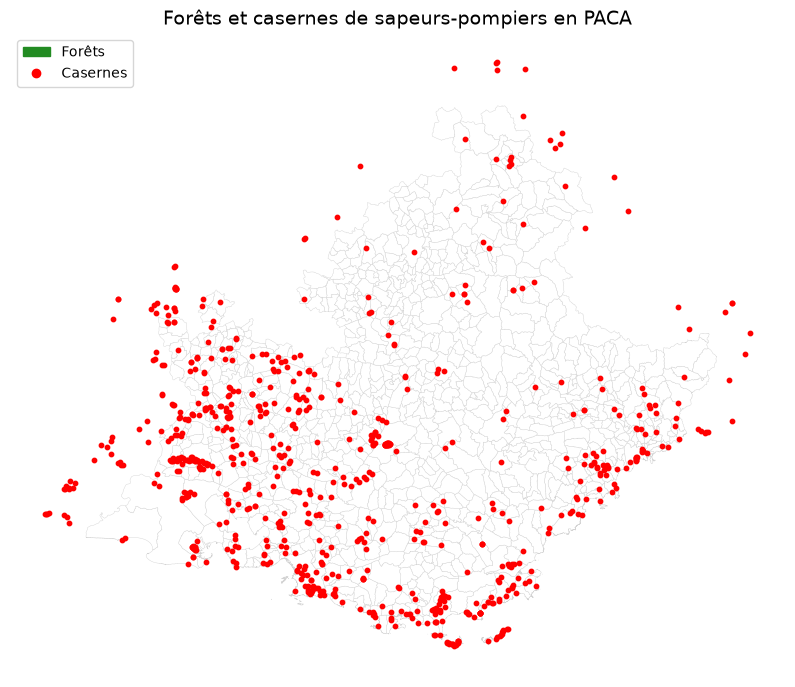

In [35]:
fig, ax = plt.subplots(figsize=(10, 9))

df_communes_paca.plot(ax=ax, color="white", edgecolor="lightgrey", linewidth=0.3)
df_forets.plot(ax=ax, color="forestgreen", alpha=0.7)
df_casernes.plot(ax=ax, color="red", markersize=10)

# légende faite à la main
legende = [
    mpatches.Patch(color="forestgreen", label="Forêts"),
    plt.Line2D([], [], marker="o", color="red", linestyle="", label="Casernes")
]
ax.legend(handles=legende, loc="upper left")
ax.set_title("Forêts et casernes de sapeurs-pompiers en PACA", fontsize=14)
ax.set_axis_off()

plt.savefig("sorties/carte1_forets_casernes.png", dpi=300, bbox_inches="tight")
plt.show()

### Carte 2 : délai moyen d'accès aux forêts par commune

c:\Users\User\AppData\Roaming\uv\python\cpython-3.12.16-windows-x86_64-none\Lib\site-packages\mapclassify\classifiers.py:1767: UserWarning: Not enough unique values in array to form 5 classes. Setting k to 1.
  self.bins = quantile(y, k=k)
c:\Users\User\AppData\Roaming\uv\python\cpython-3.12.16-windows-x86_64-none\Lib\site-packages\numpy\_core\fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\User\AppData\Roaming\uv\python\cpython-3.12.16-windows-x86_64-none\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


ValueError: zero-size array to reduction operation minimum which has no identity

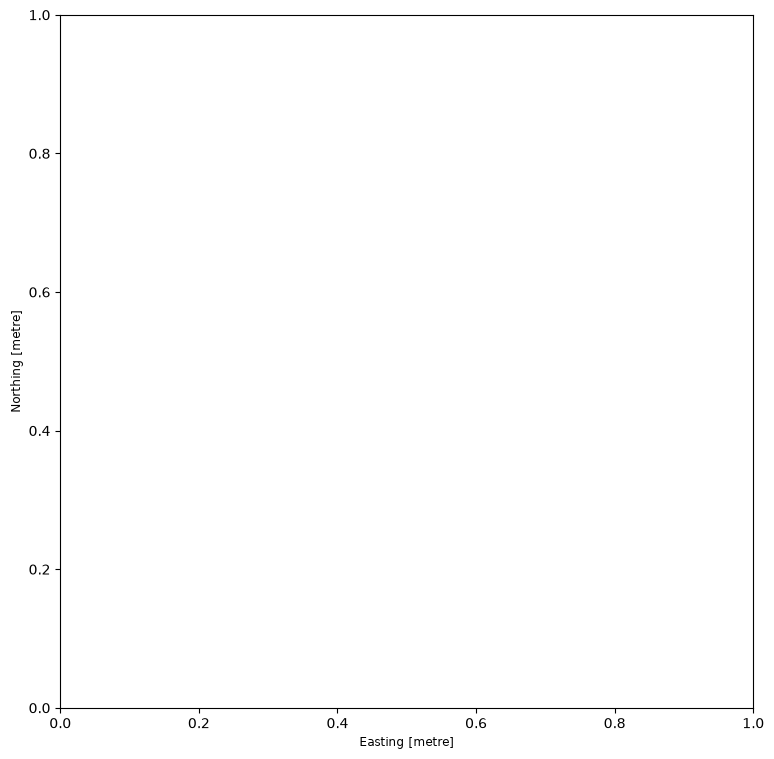

In [36]:
fig, ax = plt.subplots(figsize=(10, 9))

carte_communes.plot(
    ax=ax,
    column="delai_moyen",
    cmap="YlOrRd",
    scheme="quantiles",
    k=5,
    legend=True,
    edgecolor="grey",
    linewidth=0.2,
    missing_kwds={"color": "whitesmoke", "label": "Pas de forêt"},
    legend_kwds={"title": "Délai moyen (min)", "loc": "upper left", "fmt": "{:.0f}"}
)
df_casernes.plot(ax=ax, color="black", markersize=4)

ax.set_title("Délai théorique moyen d'accès aux forêts", fontsize=14)
ax.set_axis_off()

plt.savefig("sorties/carte2_delai_moyen.png", dpi=300, bbox_inches="tight")
plt.show()

### Carte 3 : nombre d'incendies par commune

In [ ]:
fig, ax = plt.subplots(figsize=(10, 9))

carte_communes.plot(
    ax=ax,
    column="nb_incendies",
    cmap="Reds",
    scheme="natural_breaks",
    k=5,
    legend=True,
    edgecolor="grey",
    linewidth=0.2,
    legend_kwds={"title": "Nombre d'incendies", "loc": "upper left", "fmt": "{:.0f}"}
)
ax.set_title("Nombre d'incendies enregistrés (BDIFF)", fontsize=14)
ax.set_axis_off()

plt.savefig("sorties/carte3_incendies.png", dpi=300, bbox_inches="tight")
plt.show()

### Carte 4 : typologie des communes

In [ ]:
couleurs = {
    "Prioritaire": "#c0392b",
    "Exposée mais desservie": "#f39c12",
    "Éloignée, peu de feux": "#5dade2",
    "Faible enjeu": "#d5d8dc",
    "Pas de forêt": "white"
}

fig, ax = plt.subplots(figsize=(10, 9))
legende = []

for categorie, couleur in couleurs.items():
    sous_ensemble = carte_communes[carte_communes["typologie"] == categorie]
    if len(sous_ensemble) > 0:
        sous_ensemble.plot(ax=ax, color=couleur, edgecolor="grey", linewidth=0.2)
    legende.append(mpatches.Patch(facecolor=couleur, edgecolor="grey", label=categorie))

ax.legend(handles=legende, loc="upper left", title="Typologie")
ax.set_title("Communes prioritaires : beaucoup d'incendies et délai long", fontsize=14)
ax.set_axis_off()

plt.savefig("sorties/carte4_typologie.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Graphiques

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# histogramme des délais
axes[0].hist(forets_communes["delai_min"], bins=30, color="#c0392b", edgecolor="white")
axes[0].axvline(forets_communes["delai_min"].median(), color="black", linestyle="--", label="Médiane")
axes[0].set_xlabel("Délai théorique (min)")
axes[0].set_ylabel("Nombre de forêts")
axes[0].set_title("Distribution des délais d'accès")
axes[0].legend()

# nuage de points incendies / délai
axes[1].scatter(communes_avec_foret["delai_moyen"], communes_avec_foret["nb_incendies"], alpha=0.5, color="#2c3e50")
axes[1].axvline(seuil_delai, color="grey", linestyle=":")
axes[1].axhline(seuil_incendies, color="grey", linestyle=":")
axes[1].set_xlabel("Délai moyen (min)")
axes[1].set_ylabel("Nombre d'incendies")
axes[1].set_title("Incendies et délai par commune")

plt.tight_layout()
plt.savefig("sorties/graphiques.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Limites
- **Distance à vol d'oiseau × 1,3** : c'est une approximation. Un calcul sur le réseau routier réel (OSRM, osmnx) serait plus juste, surtout en montagne (04, 05, 06).
- **Caserne la plus proche ≠ caserne qui intervient.** La disponibilité et les moyens des casernes ne sont pas pris en compte.
- **Un point par forêt** : pour les grands massifs, le délai jusqu'à la lisière est plus court que le délai jusqu'au point intérieur.
- **Qualité OSM** : certaines casernes peuvent être absentes ou mal étiquetées.